In [2]:
# %matplotlib inline
from datetime import datetime
import time
from astropy.time import Time, TimeDelta

import pandas as pd
import numpy as np
from scipy.ndimage import uniform_filter1d
import os
import matplotlib.pyplot as plt
from lsst_efd_client import EfdClient 
from lsst.summit.utils import ConsDbClient #type:ignore

vscode= True 

if vscode == True:
    URL = "https://usdf-rsp.slac.stanford.edu/consdb" #for vscode 
    tk = os.environ["CONSDB_TOKEN"]  # set in .env (see README)
    cdb_client = ConsDbClient(URL,token=tk)
else:
    URL = "http://consdb-pq.consdb:8080/consdb"  
    os.environ["no_proxy"] += ",.consdb"
    cdb_client = ConsDbClient(URL)

In [3]:
client = EfdClient('usdf_efd')
# print(dir(client.influx_client))
MTCAM_client = EfdClient('usdf_efd', db_name="lsst.MTCamera")

original_time_start = Time("2025-12-08T00:00:00", scale="utc", format="isot")
original_time_end = original_time_start + TimeDelta(3.0 * 3600, format='sec')
time_start = original_time_start
time_end = original_time_end

# Use the exact same UTC window used for EFD queries.
time_start_utc = time_start.utc.isot
time_end_utc = time_end.utc.isot

query = f"""
    SELECT
        e.obs_start AT TIME ZONE 'UTC' AS obs_start_utc,
        te.mt_m1m3_glycol_loop_temperature_above_mirror_temp
    FROM cdb_lsstcam.exposure AS e
    JOIN efd_lsstcam.exposure_efd AS te
        USING (day_obs, seq_num, exposure_id)
    WHERE
        e.obs_start >= TIMESTAMP '{time_start_utc}'
        AND e.obs_start <= TIMESTAMP '{time_end_utc}'
    ORDER BY e.obs_start
"""

m1m3_consdb = cdb_client.query(query).to_pandas()
m1m3_consdb['obs_start_utc'] = pd.to_datetime(m1m3_consdb['obs_start_utc'], utc=True)
m1m3_consdb = m1m3_consdb.set_index('obs_start_utc').sort_index()

print(f"ConsDB rows in window: {len(m1m3_consdb)}")
print(m1m3_consdb)

def align_consdb_to_efd_index(consdb_df, efd_df, value_col, tolerance='10min'):
    """Map ConsDB values onto EFD timestamps (nearest sample within tolerance)."""
    efd_index = pd.to_datetime(efd_df.index, utc=True)
    left = pd.DataFrame({'ts': efd_index}).sort_values('ts')
    right = consdb_df[[value_col]].copy().reset_index()
    right = right.rename(columns={consdb_df.index.name: 'ts'}).sort_values('ts')

    aligned = pd.merge_asof(
        left,
        right,
        on='ts',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance),
    ).set_index('ts')

    aligned.index.name = None
    return aligned[value_col]

ConsDB rows in window: 18
                                 mt_m1m3_glycol_loop_temperature_above_mirror_temp
obs_start_utc                                                                     
2025-12-08 02:17:12.636000+00:00                                           9.14795
2025-12-08 02:18:58.424000+00:00                                              None
2025-12-08 02:26:03.866000+00:00                                          9.238617
2025-12-08 02:29:13.246000+00:00                                              None
2025-12-08 02:31:17.376000+00:00                                          9.190827
2025-12-08 02:33:21.515000+00:00                                              None
2025-12-08 02:35:25.977000+00:00                                          9.351967
2025-12-08 02:37:30.454000+00:00                                          9.368944
2025-12-08 02:39:34.635000+00:00                                              None
2025-12-08 02:41:38.773000+00:00                             

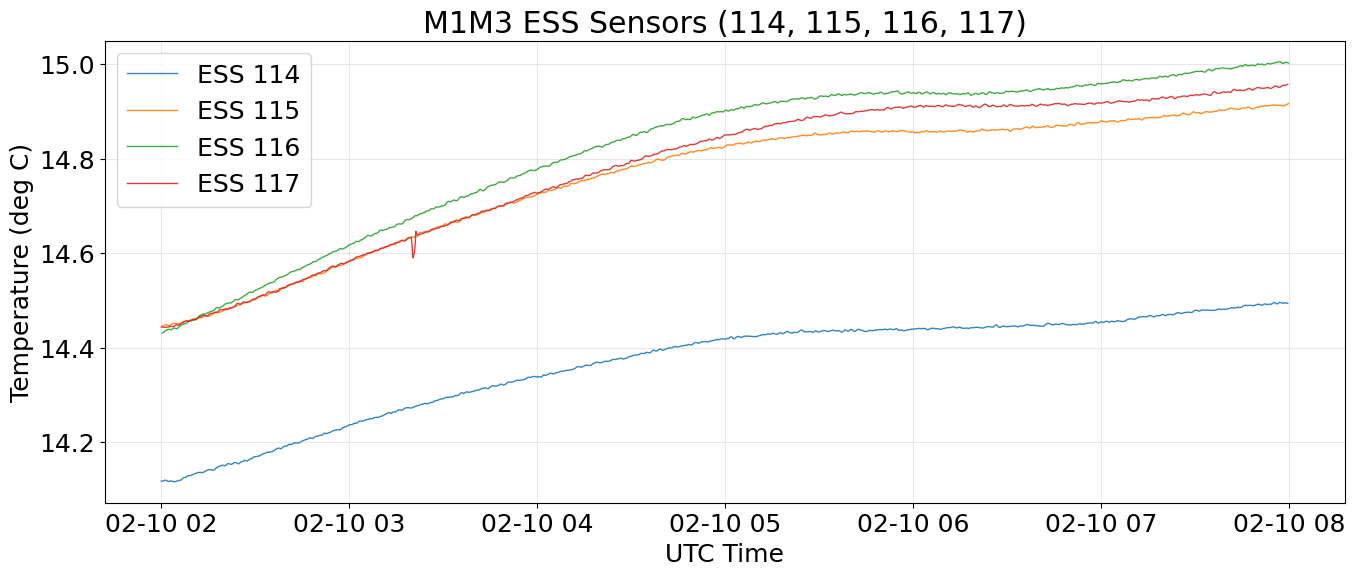

In [40]:
indices = [114, 115, 116, 117]
frames = []

for idx in indices:
    df = await client.select_time_series(
        'lsst.sal.ESS.temperature',
        fields='*',
        start=time_start,
        end=time_end,
        index=idx
    )
    if not df.empty:
        df = df.copy()
        temp_cols = [f"temperatureItem{i}" for i in range(16) if f"temperatureItem{i}" in df.columns]
        df[temp_cols] = df[temp_cols].apply(pd.to_numeric, errors="coerce")

        # Mean across channels for this ESS index (per timestamp)
        df["temperature_mean"] = df[temp_cols].mean(axis=1, skipna=True)
        df["ess_index"] = idx
        frames.append(df[["temperature_mean", "ess_index"]])

# Plot the 4 sensors in one figure
plt.figure(figsize=(16, 6))
if frames:
    m1m3_per_index = pd.concat(frames).sort_index()

    for idx in indices:
        series = m1m3_per_index[m1m3_per_index["ess_index"] == idx]["temperature_mean"]
        if series.empty:
            continue

        # Ensure one value per timestamp, then smooth/downsample for readability
        series = series.groupby(level=0).mean().sort_index()
        series = series.resample("15s").mean().interpolate("time")
        series_smooth = series.rolling("1min", center=True).mean()

        plt.plot(series_smooth.index, series_smooth.values, label=f"ESS {idx}", linewidth=1.0, alpha=0.9)

    plt.title("M1M3 ESS Sensors (114, 115, 116, 117)")
    plt.xlabel("UTC Time")
    plt.ylabel("Temperature (deg C)")
    plt.grid(True, alpha=0.3)
    plt.legend()
else:
    plt.title("No data for ESS indices 114, 115, 116, 117 in selected window")
plt.show()

In [ ]:
changes=['2026-01-14T02:00:00','2025-12-08T00:00:00','2025-12-11T00:00:00','2025-12-13T00:00:00','2026-02-07T02:00:00','2026-02-10T02:00:00'] #['2026-01-29T00:34:25.6'] #,'2026-01-13T04:54:17.1','2026-01-11T01:30:17.4','2026-01-11T07:45:03.3','2026-01-10T02:09:45.3','2026-01-10T07:01:16.4']
for time in changes:
    original_time_start = Time(time, scale="utc", format="isot")
    original_time_end = original_time_start+TimeDelta(4.0*3600, format='sec')
    time_start = original_time_start
    time_end= original_time_end
    
    filt_log=(await client.select_time_series(
    'lsst.sal.MTCamera.command_setFilter',
    fields='*',
    start=time_start,
    end=time_end
    ))

    if len(filt_log.index)<3: continue
        
    env_temp=(await client.select_time_series(
    'lsst.sal.ESS.temperature',
    fields='*',
    start=time_start,
    end=time_end,
    index=111
))


    splytemp=(await client.select_time_series(
    "lsst.sal.MTCamera.utiltrunk_VPC",
    fields=['splyAirTemp','retnAirTemp',],
    start=time_start,
    end=time_end
    ))
    plt.figure(figsize=(18,6))
    cam_temp2=(await client.select_time_series(
    "lsst.sal.MTCamera.utiltrunk_Body",
    fields=['l1XMinusTemp', 'l1XPlusTemp','l1YMinusTemp','l1YPlusTemp',
           'l2XMinusTemp', 'l2XPlusTemp','l2YMinusTemp','l2YPlusTemp'],
    start=time_start,
    end=time_end
    ))
    # print(cam_temp)
    mean_L1 = cam_temp2[['l1XMinusTemp', 'l1XPlusTemp','l1YMinusTemp','l1YPlusTemp']].mean(axis=1)
    mean_L2 = cam_temp2[['l2XMinusTemp', 'l2XPlusTemp','l2YMinusTemp','l2YPlusTemp']].mean(axis=1)
    for probe in ['splyAirTemp','retnAirTemp',] :
        plt.plot(splytemp[probe],label=probe)
        rolling = pd.Series(splytemp[probe].squeeze()).rolling(window=15, center=True).mean()
        plt.plot(splytemp.index,rolling,color='orange', lw=3)
    [plt.axvline(event) for event in filt_log.index]
    plt.plot(mean_L1,label ='L1')
    plt.plot(mean_L2,label='L2')
    plt.legend()
    plt.show()
#--------------------------------------------------------------------------------------------------
    cam_temp=(await MTCAM_client.select_time_series(
        "lsst.MTCamera.utiltrunk_body",
        fields=['CamBodyXPlusTemp','CamBodyYMinusTemp','CamBodyYPlusTemp'],
        start=time_start,
        end=time_end
    ))
   
    plt.figure(figsize=(18,6))
    for probe in ['CamBodyXPlusTemp','CamBodyYMinusTemp','CamBodyYPlusTemp'] :
        rolling = pd.Series(cam_temp[probe].dropna().squeeze()).rolling(window=10, center=True).mean()
        # plt.plot(cam_temp[probe].dropna())
        
        plt.plot(rolling,lw=4,label=probe)
    [plt.axvline(event) for event in filt_log.index]

    plt.plot(env_temp['temperatureItem0'],label='Env Temp')
    plt.legend()
    plt.show()
#--------------------------------------------------------------------------------------------------
    
    autoch_temp=(await MTCAM_client.select_time_series(
        "lsst.MTCamera.fcs_autochanger_temperatures",
        fields='*',
        start=time_start,
        end=time_end
    ))
    
    # print(autoch_temp.columns)
    # rolling = pd.Series(autoch_temp.squeeze()).rolling(window=50, center=True).mean()
    plt.figure(figsize=(18,6))
    for probe in ['clampMotorXMinus','clampMotorXPlus','clampMotorYMinus','cellXMinus'] :
        # plt.plot(autoch_temp['temperature'][autoch_temp['Location']==probe],label=probe)
        rolling = pd.Series(autoch_temp['temperature'][autoch_temp['Location']==probe].dropna().squeeze()).rolling(window=10, center=True).mean()
        plt.plot(rolling,label=probe)
    [plt.axvline(event) for event in filt_log.index]
    plt.plot(mean_L1,label ='L1')
    plt.plot(mean_L2,label='L2')
    plt.plot(env_temp['temperatureItem0'],label='Env Temp')
    plt.legend()
    plt.show()


#--------------------------------------------------------------------------------------------------
    carousel_breaks_temp=(await MTCAM_client.select_time_series(
    "lsst.MTCamera.fcs_carousel_brakes",
    fields='*',
    start=time_start,
    end=time_end
    ))
    plt.figure(figsize=(18,6))
    [plt.axvline(event) for event in filt_log.index]
    
    for bay in ['bayD','bayI','bayN','bayX'] :
        plt.plot(carousel_breaks_temp['temperature'][carousel_breaks_temp['Bay']==bay],label=bay)
    # plt.plot(carousel_breaks_temp['temperature'].dropna(),label='Carousel breaks')
    plt.plot(env_temp['temperatureItem0'],label='Env Temp')
    plt.legend()
    plt.show()

    print('#--------------------------------------------------------------------------------------------------')
# print(carousel_breaks_temp)


#--------------------------------------------------------------------------------------------------




#--------------------------------------------------------------------------------------------------




#--------------------------------------------------------------------------------------------------


#add L1L2 medie con de soli segnali facendo la media dei 4 delle lenti

In [ ]:
 query = f"""
    SELECT
        e.obs_start AT TIME ZONE 'UTC' AS obs_start_utc,
        te.mt_m1m3_glycol_loop_temperature_above_mirror_temp
    FROM cdb_lsstcam.exposure AS e
    JOIN efd_lsstcam.exposure_efd AS te
        USING (day_obs, seq_num, exposure_id)
    WHERE
        e.obs_start >= TIMESTAMP '{time_start_utc}'
        AND e.obs_start <= TIMESTAMP '{time_end_utc}'
    ORDER BY e.obs_start
    """

    m1m3_consdb = cdb_client.query(query).to_pandas()
    m1m3_consdb['obs_start_utc'] = pd.to_datetime(
        m1m3_consdb['obs_start_utc'],
        format='ISO8601',
        utc=True,
        errors='coerce',
    )
    m1m3_consdb = m1m3_consdb.dropna(subset=['obs_start_utc']).set_index('obs_start_utc').sort_index()


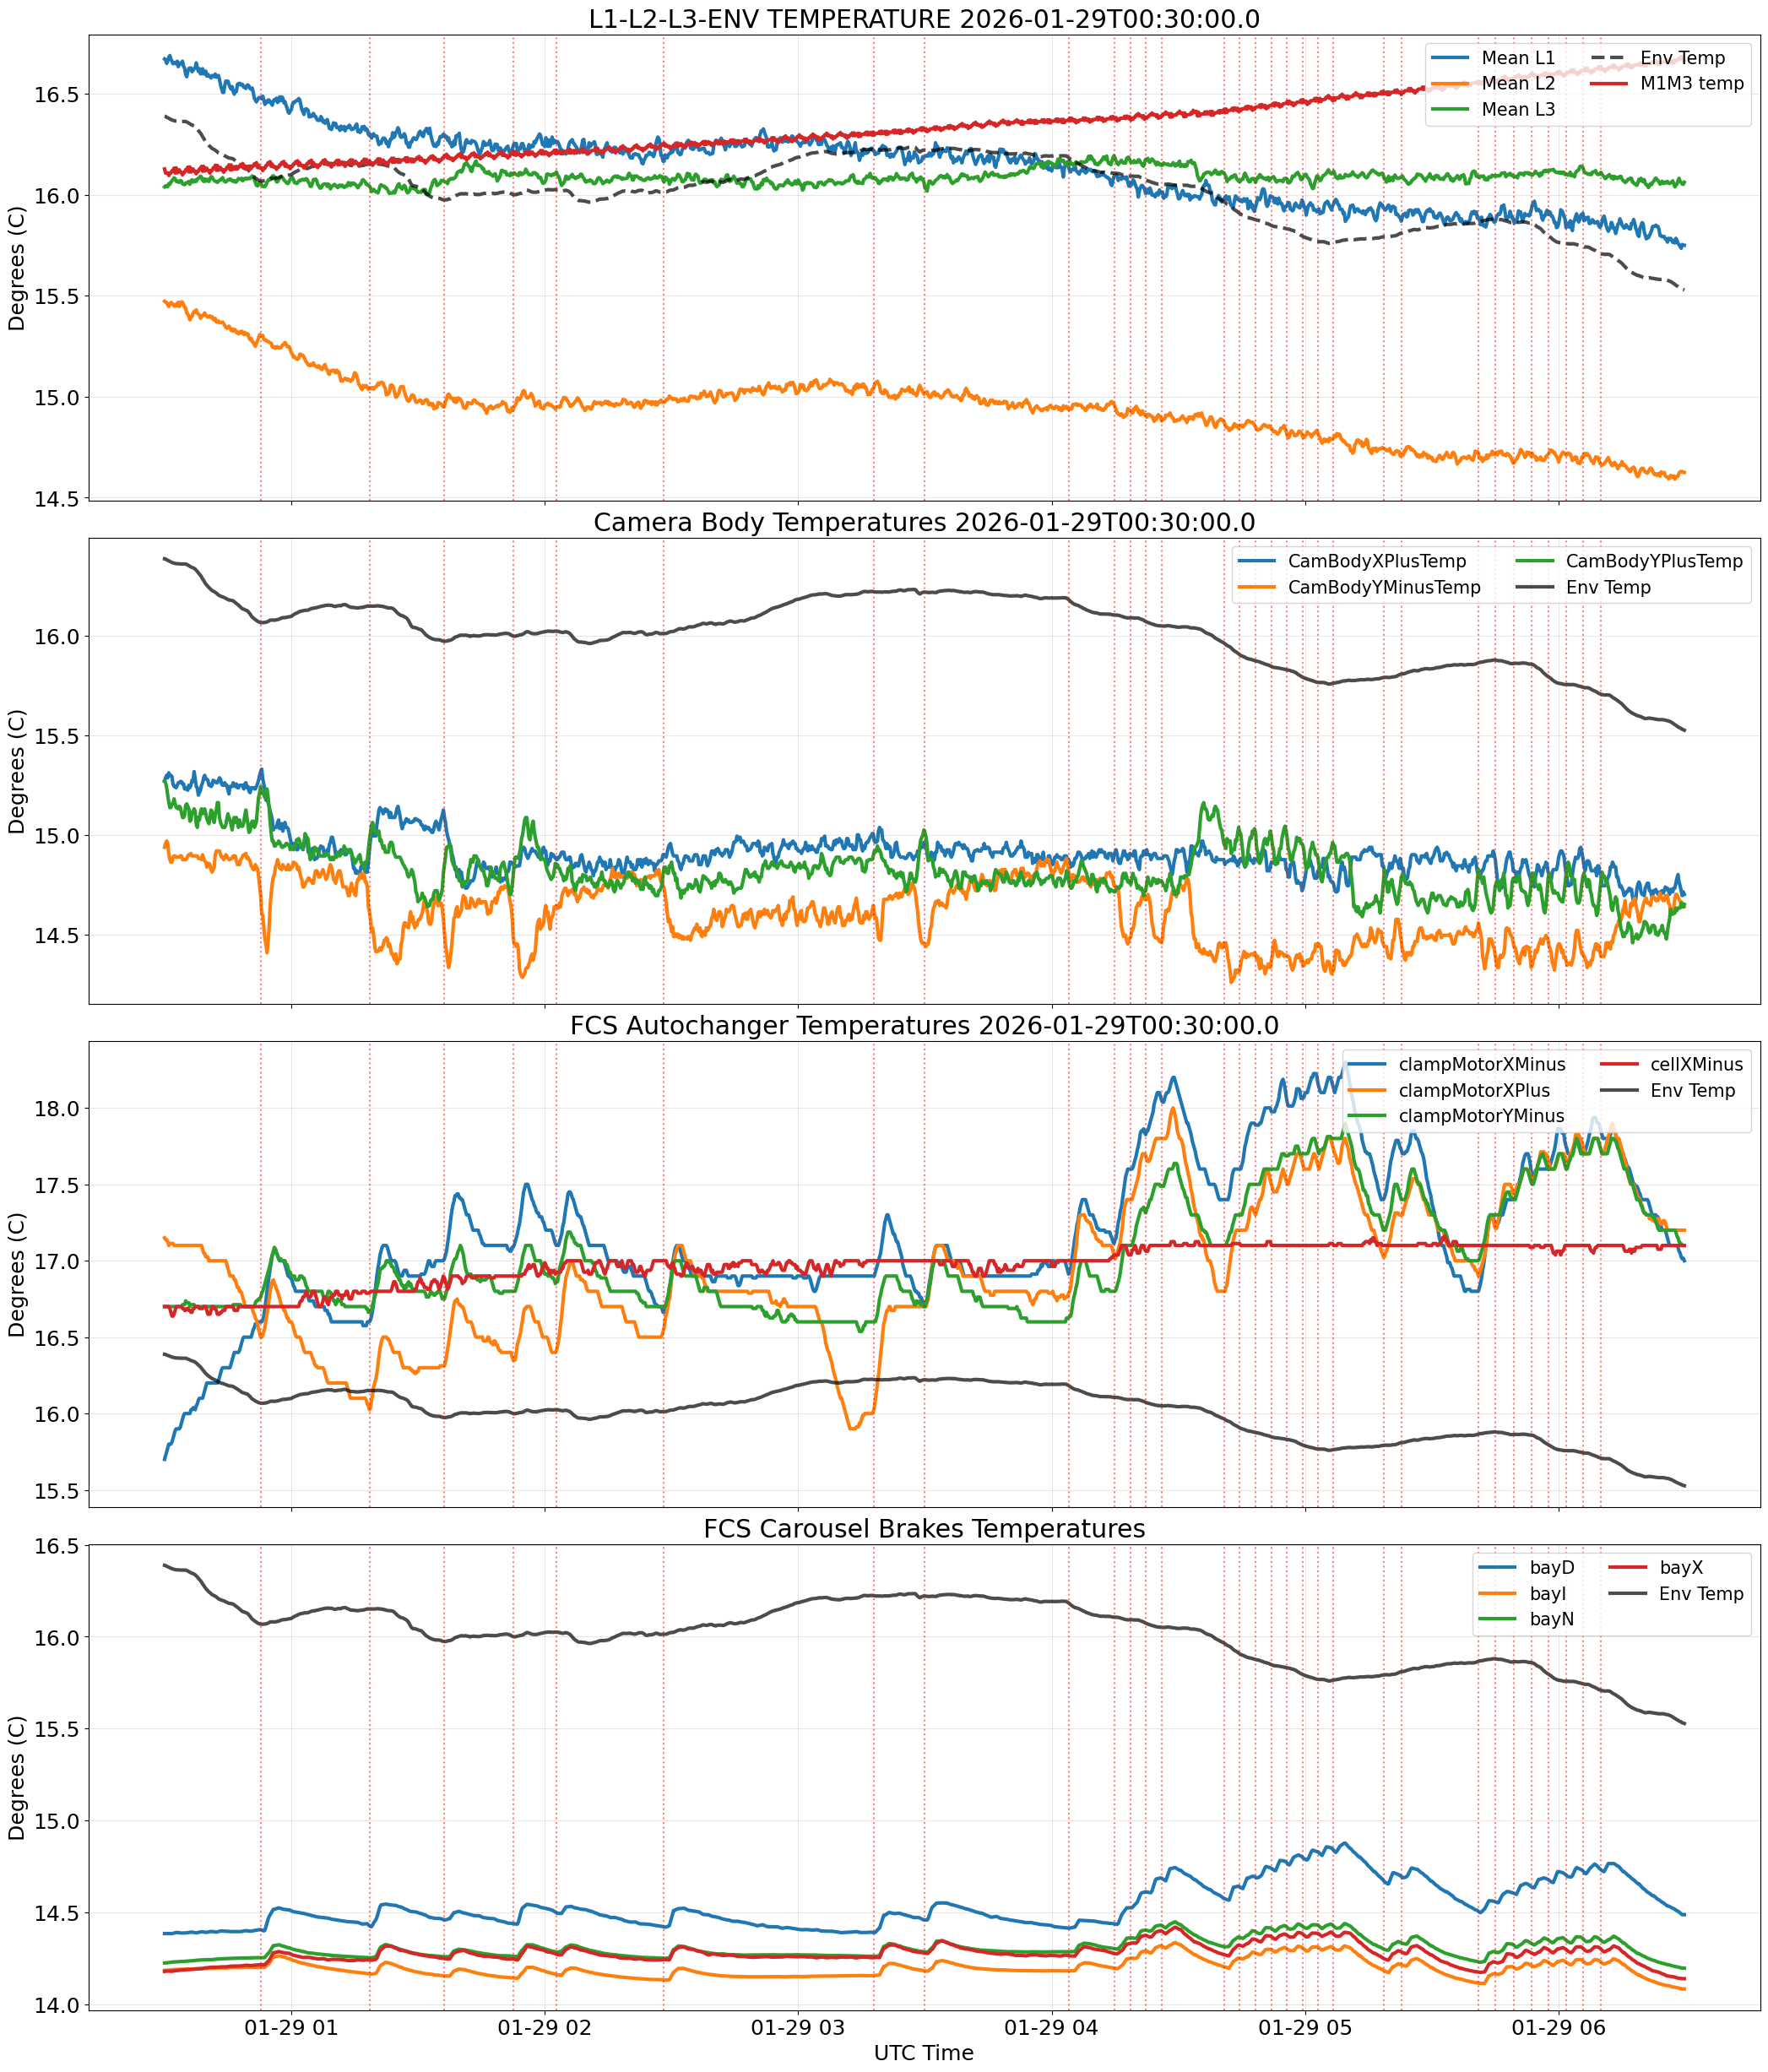

#----------------------------------------------------------------------------------------------------


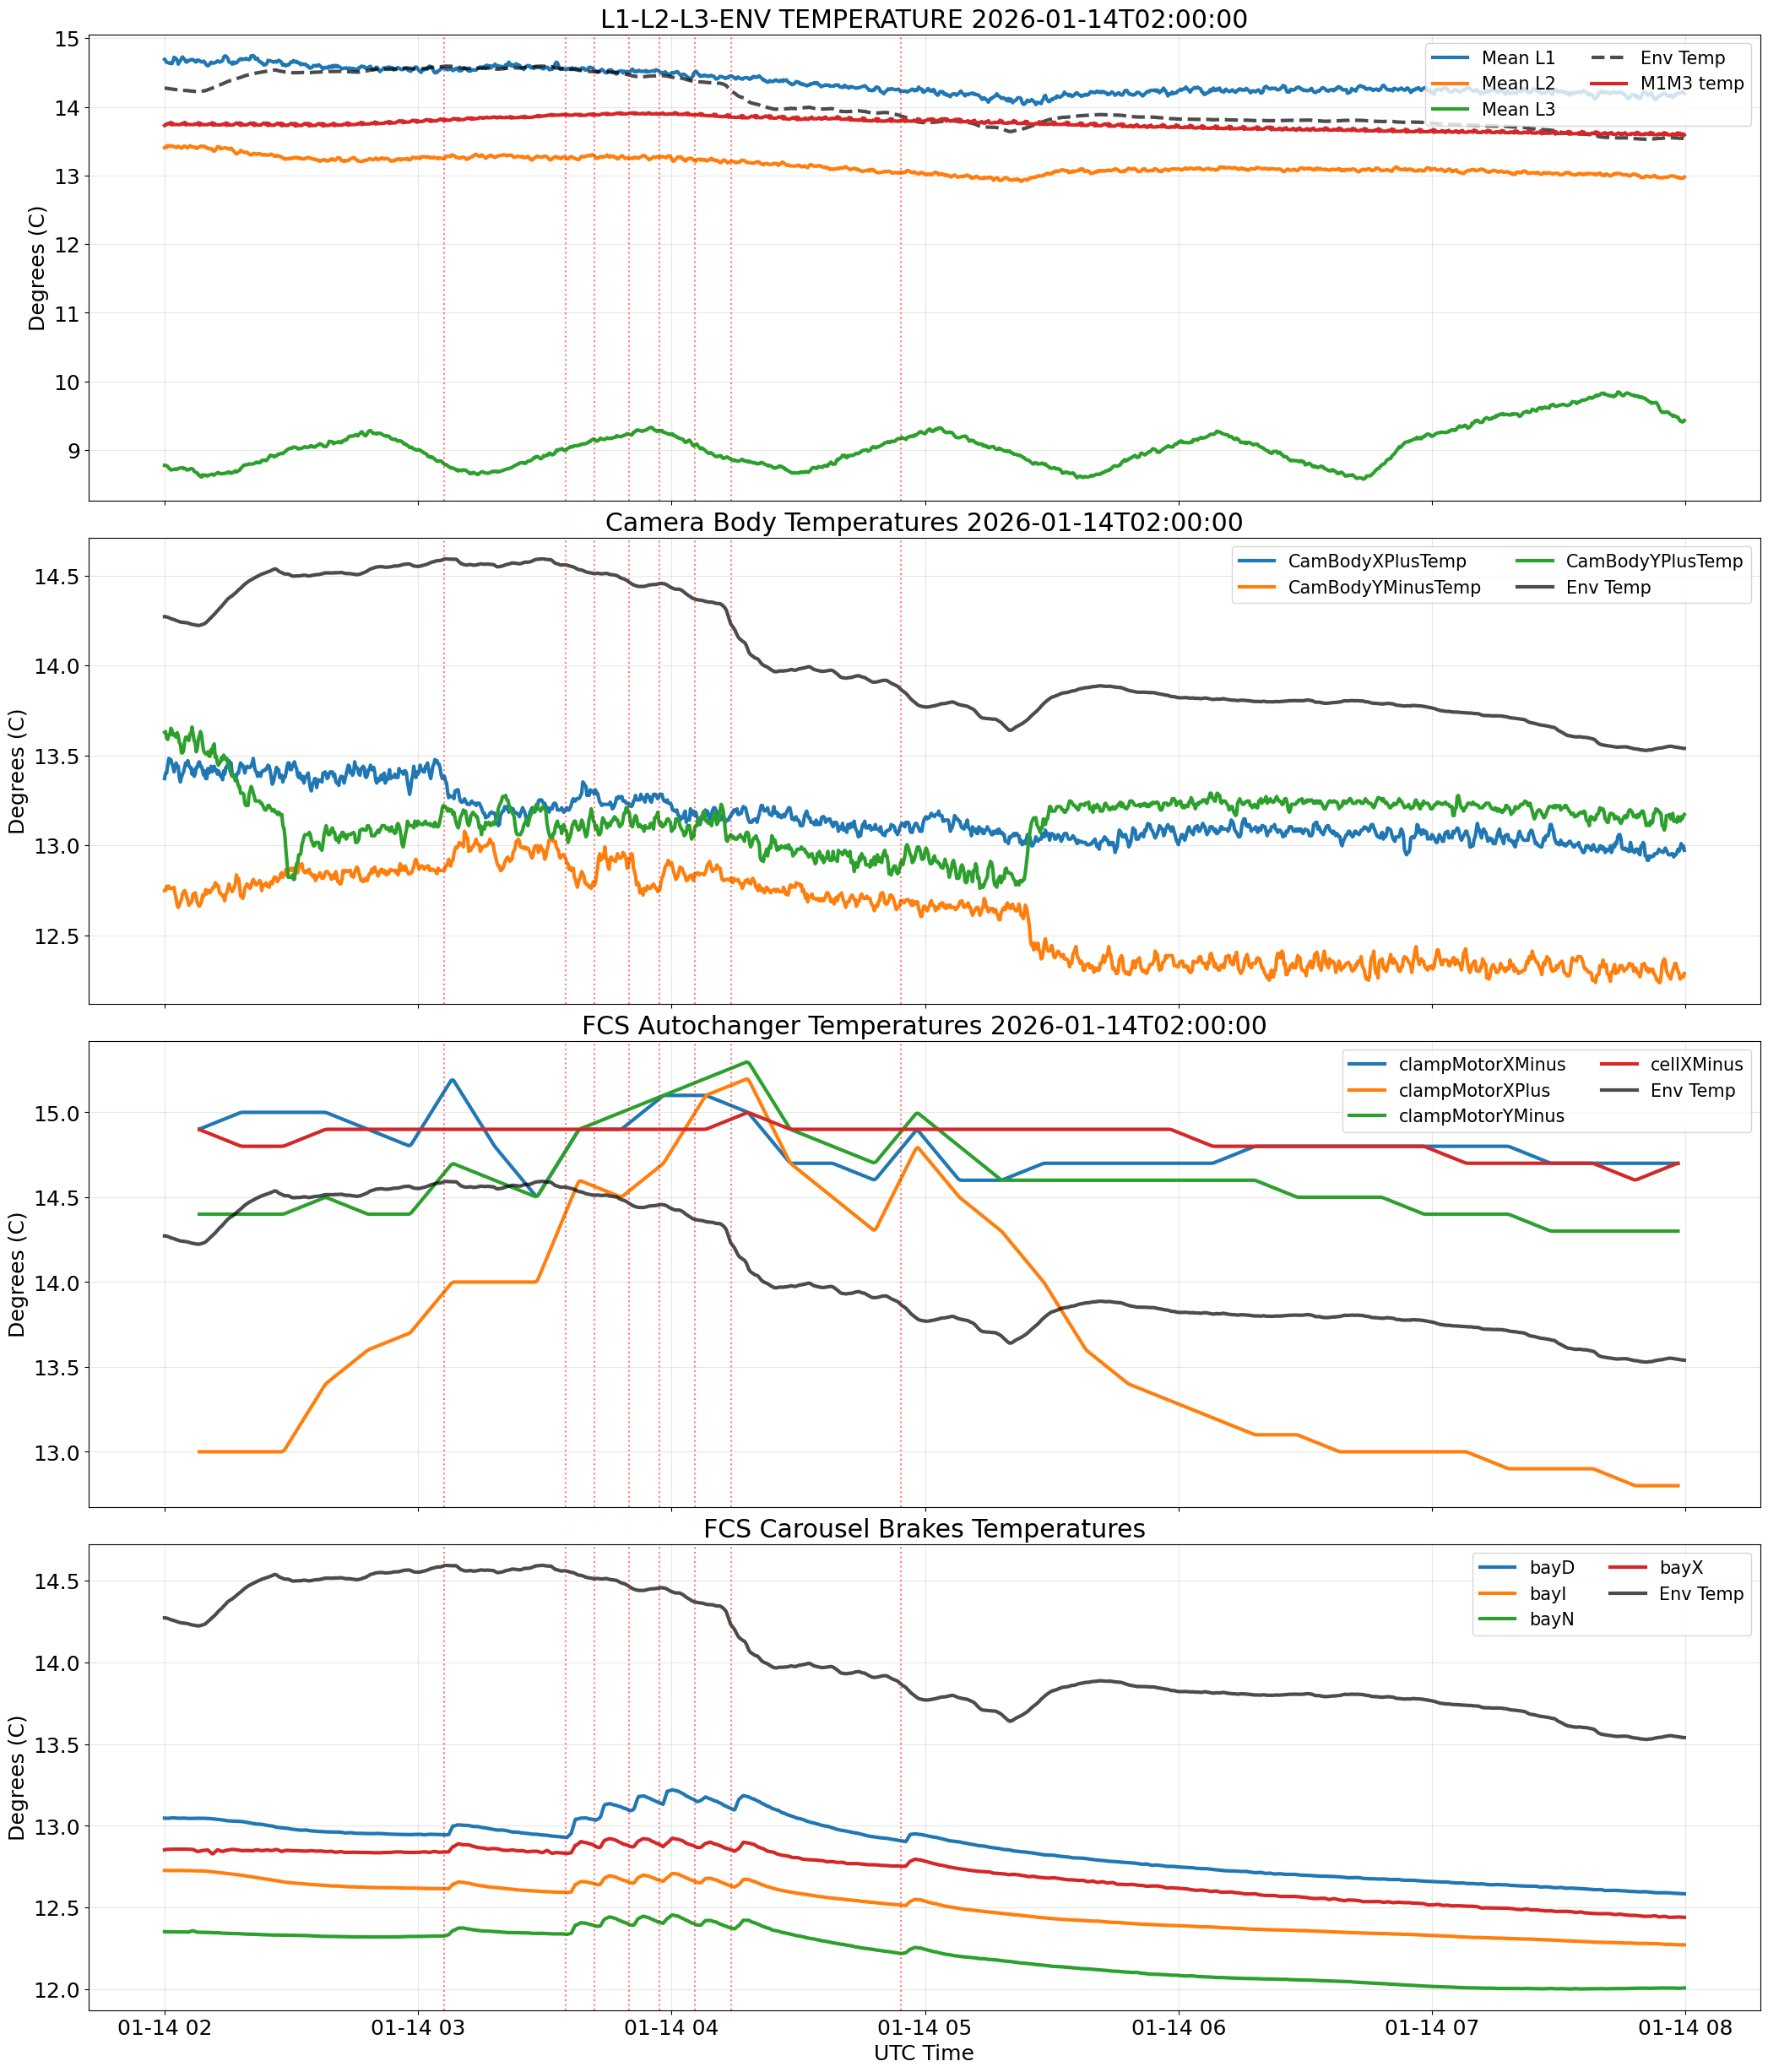

#----------------------------------------------------------------------------------------------------


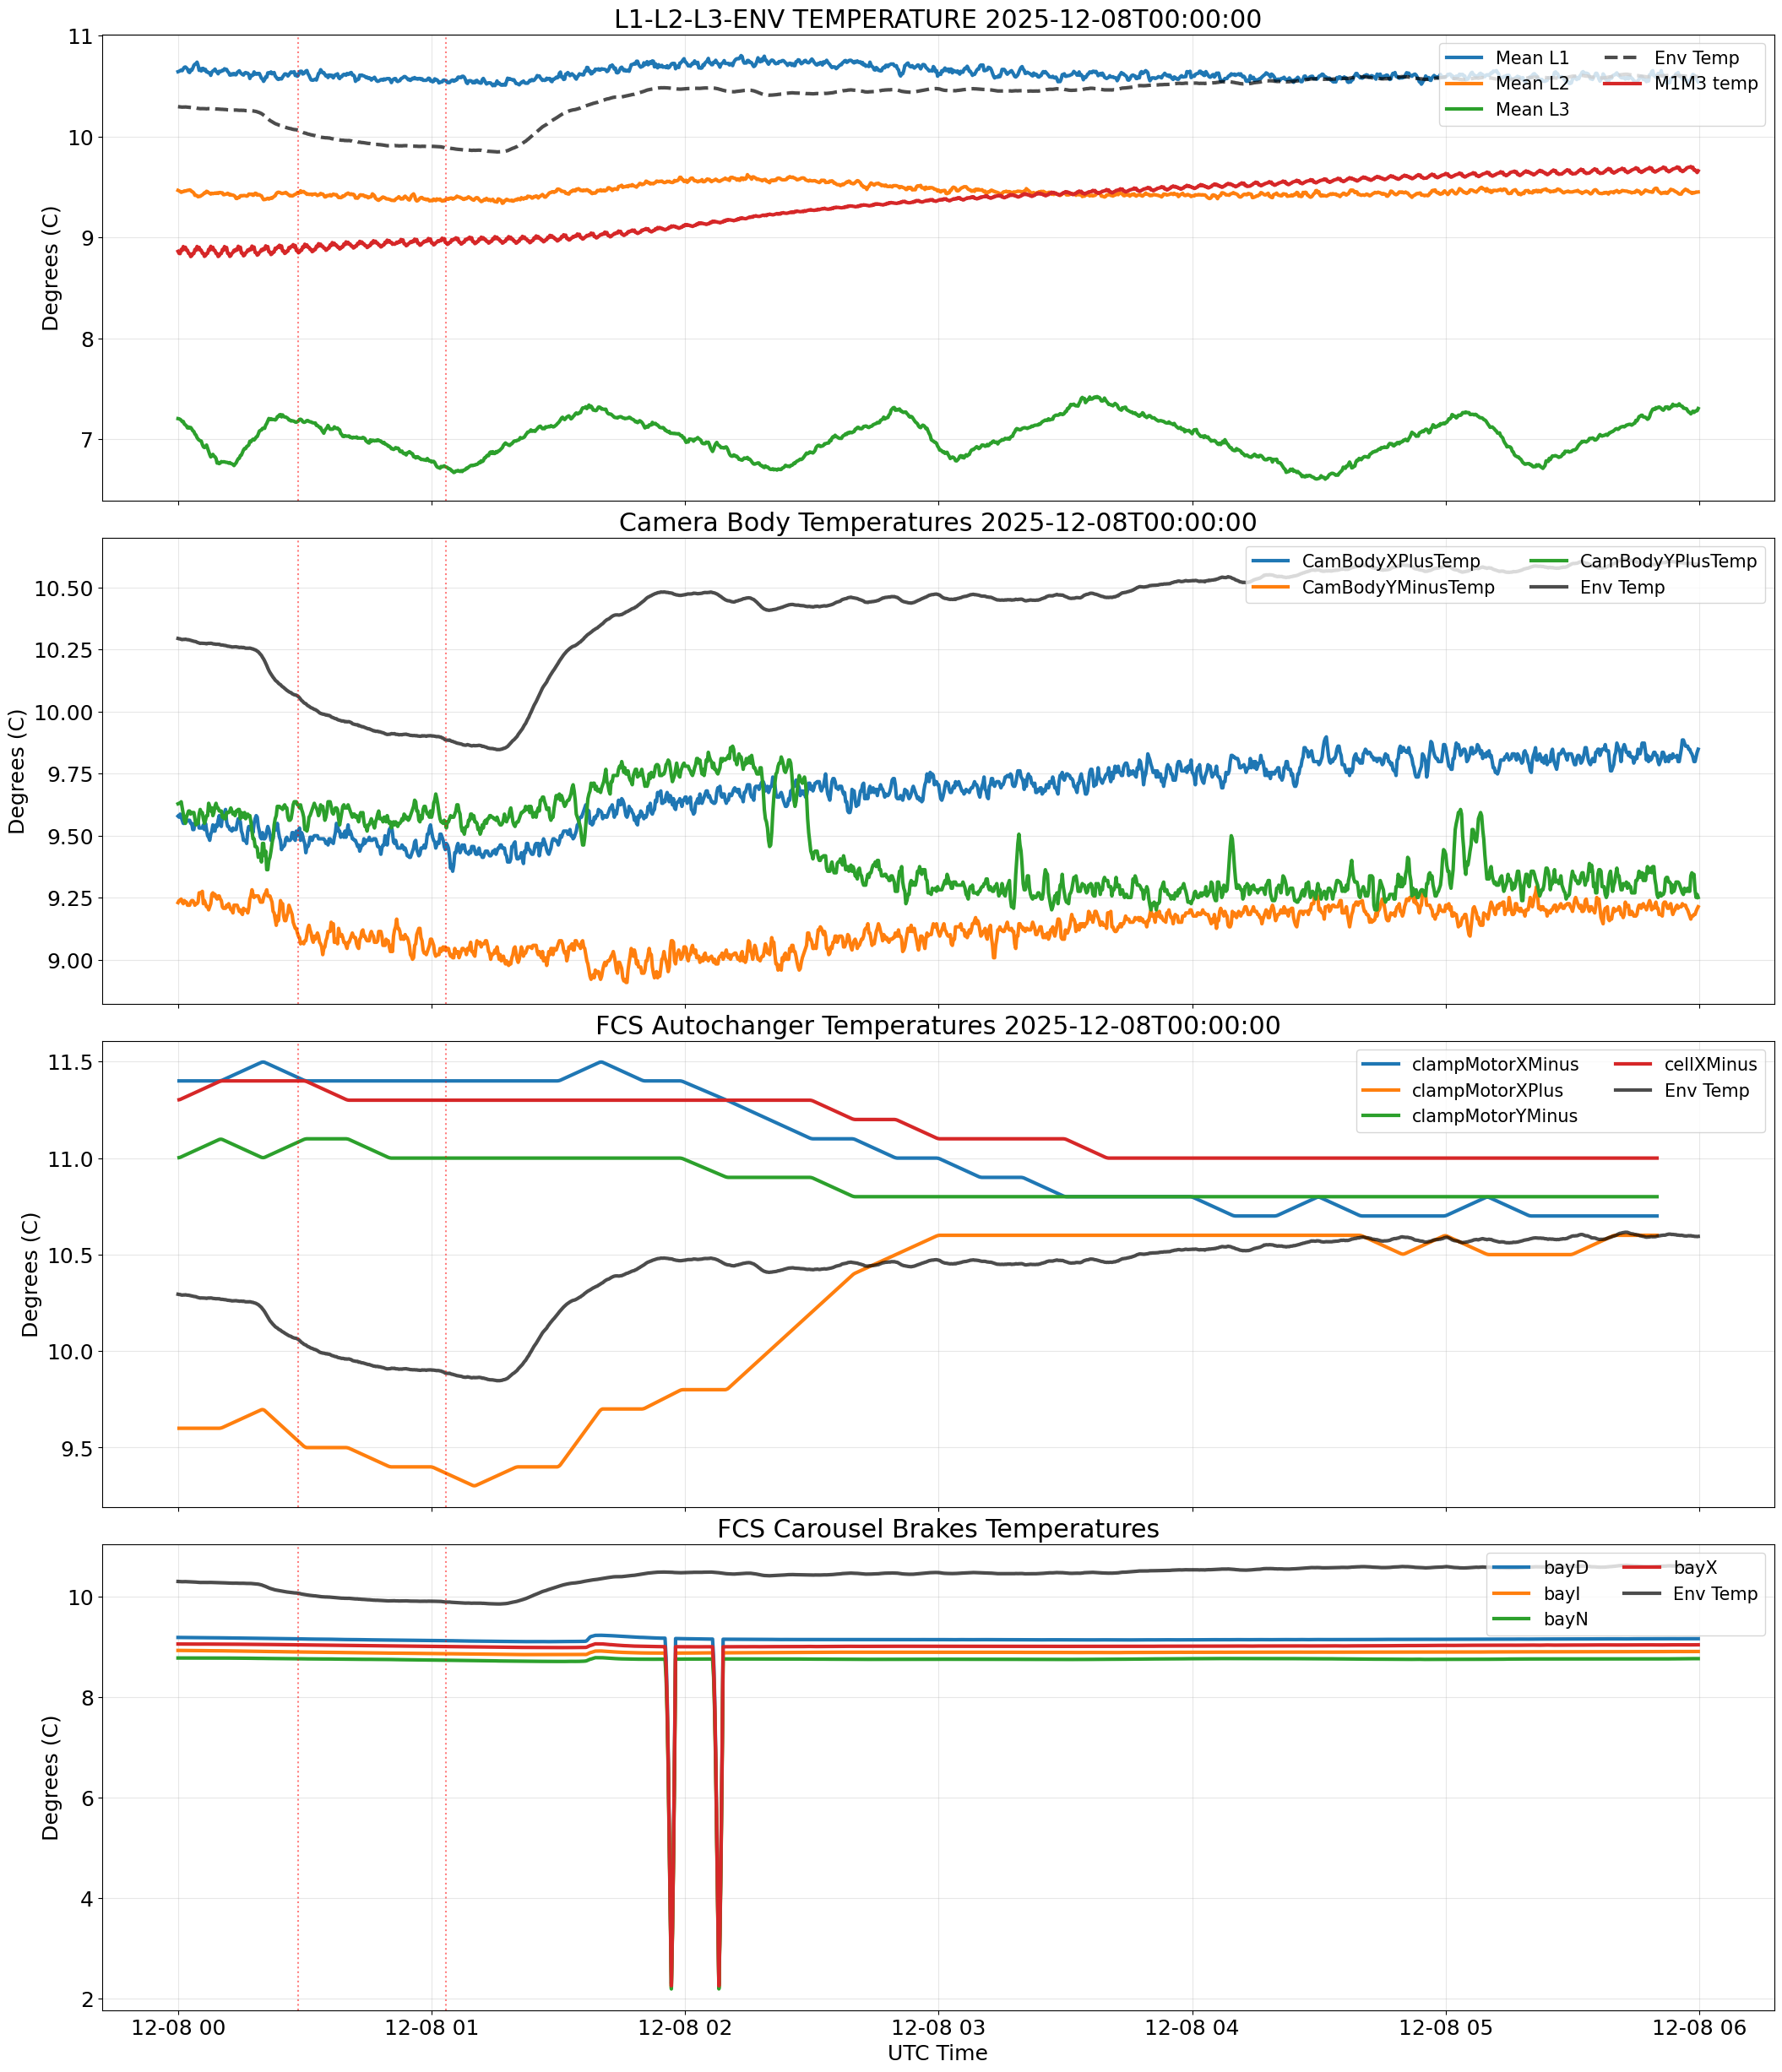

#----------------------------------------------------------------------------------------------------


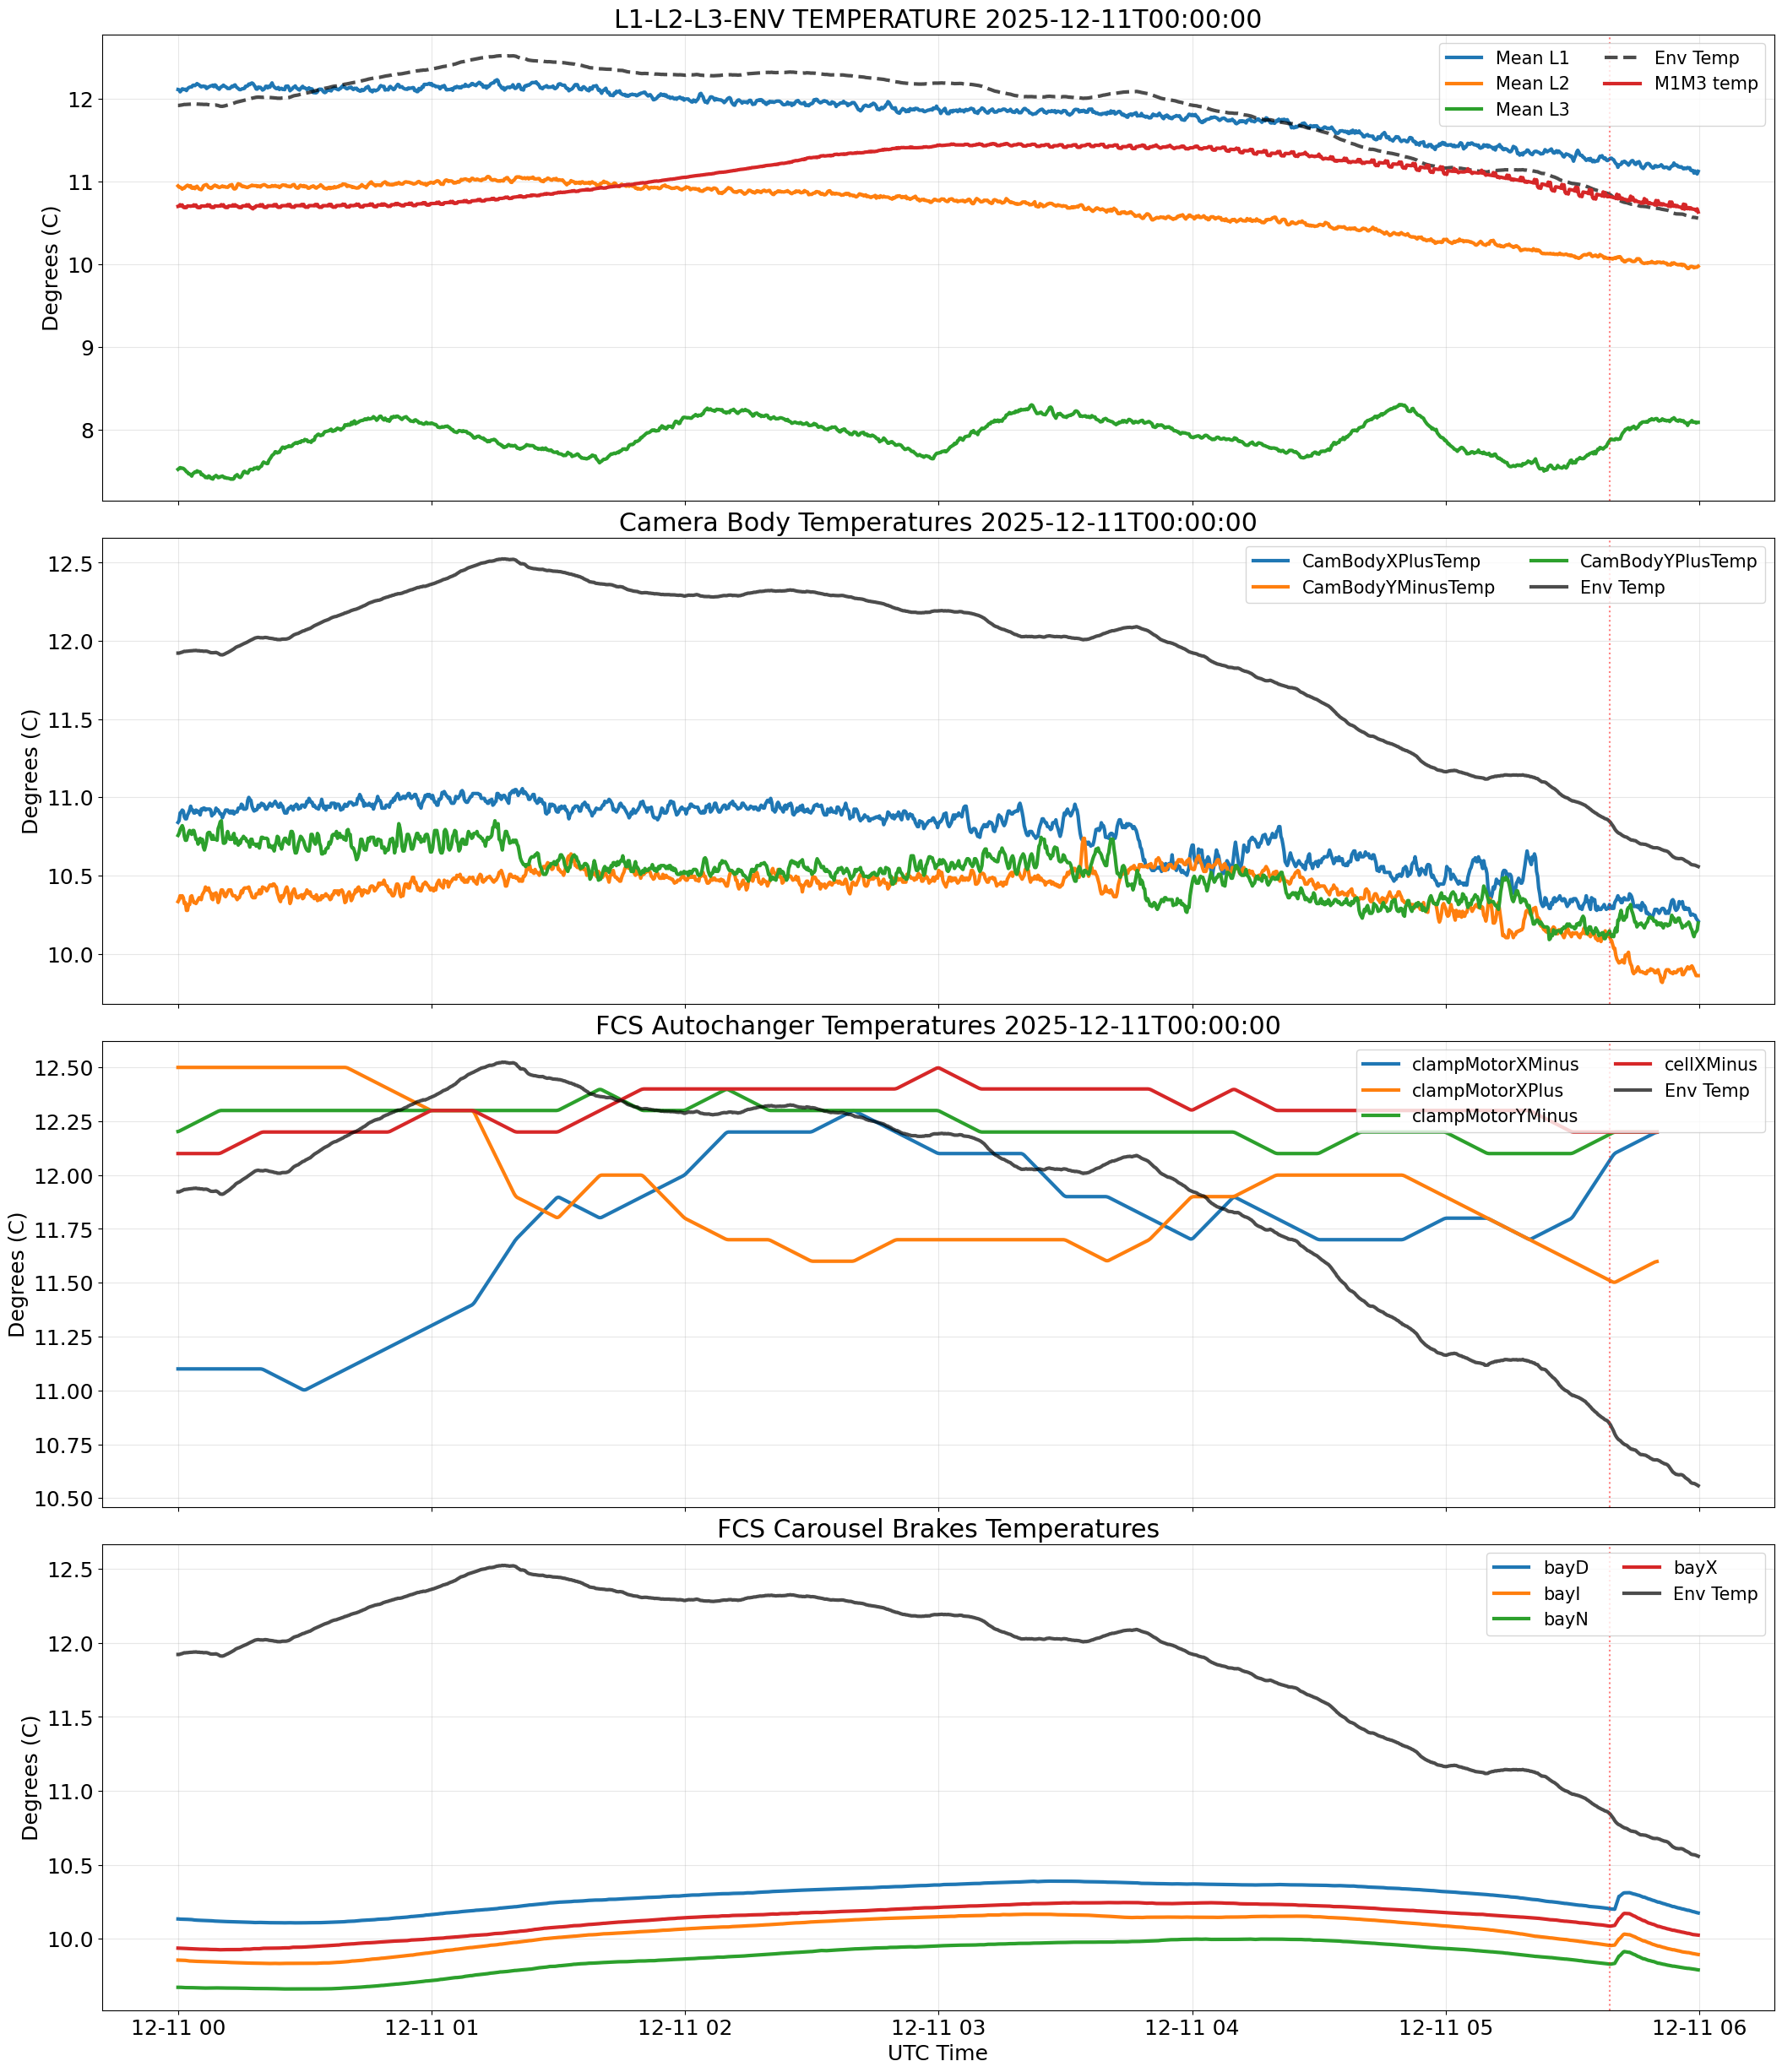

#----------------------------------------------------------------------------------------------------


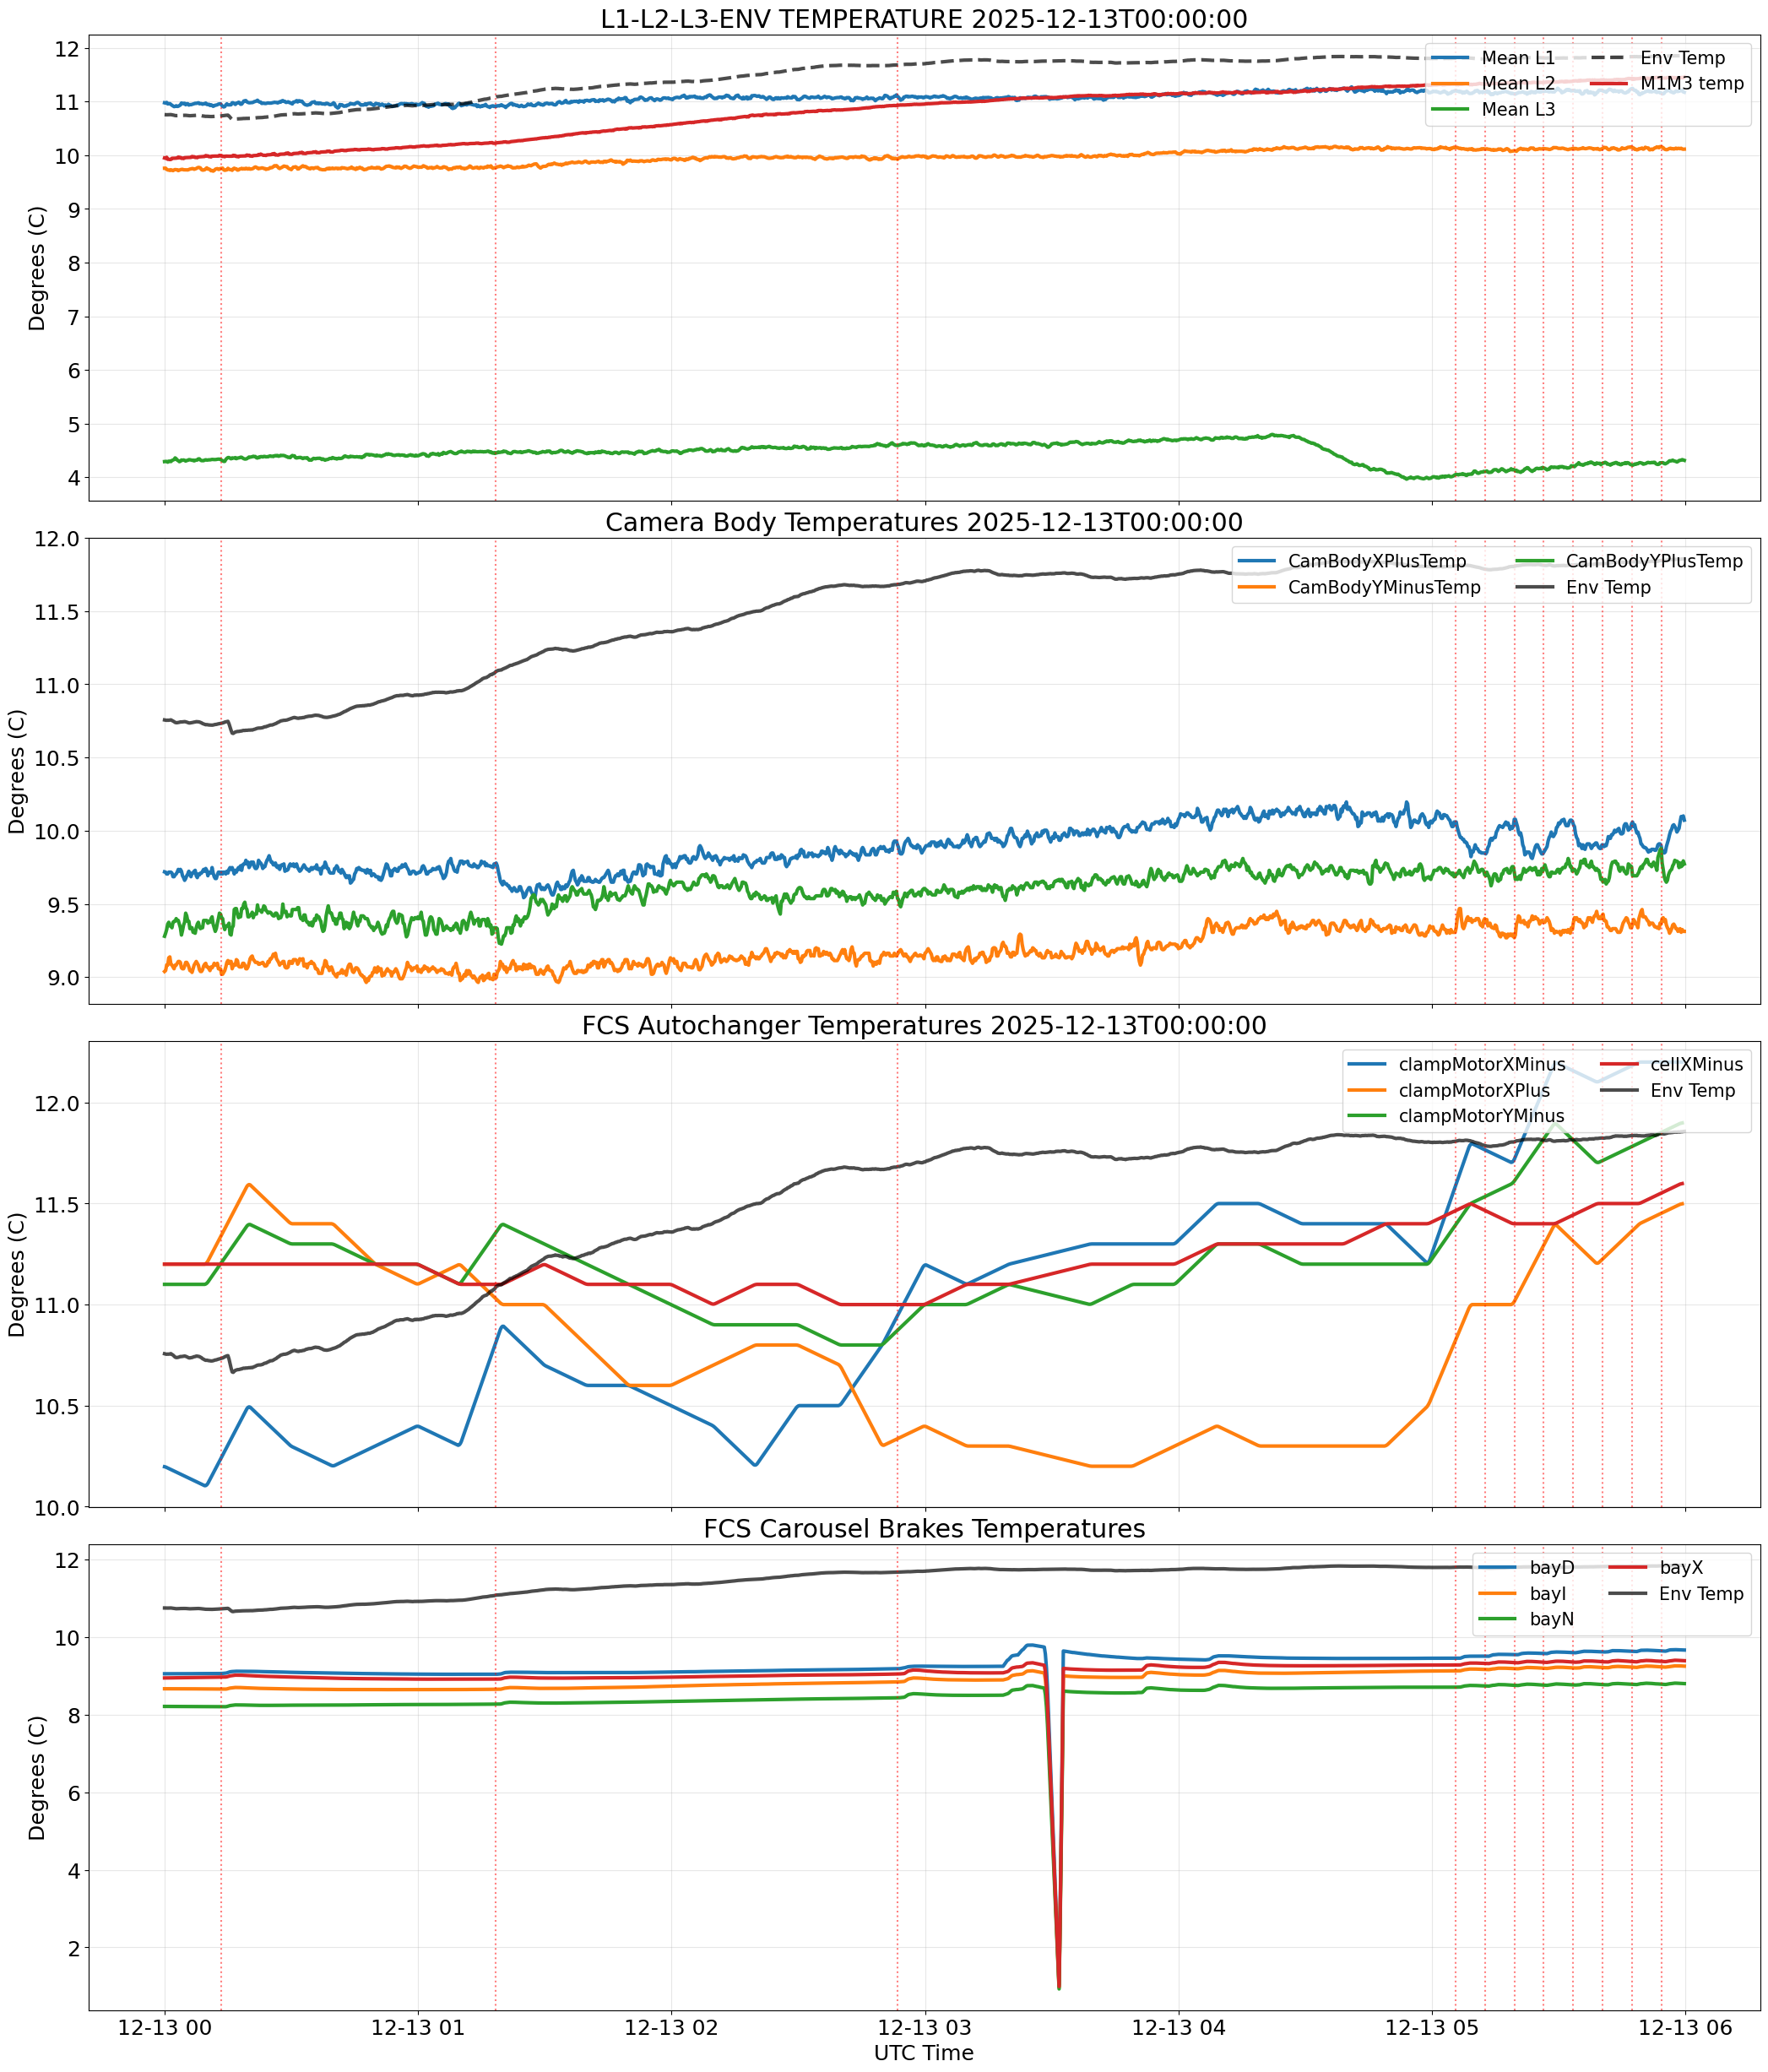

#----------------------------------------------------------------------------------------------------


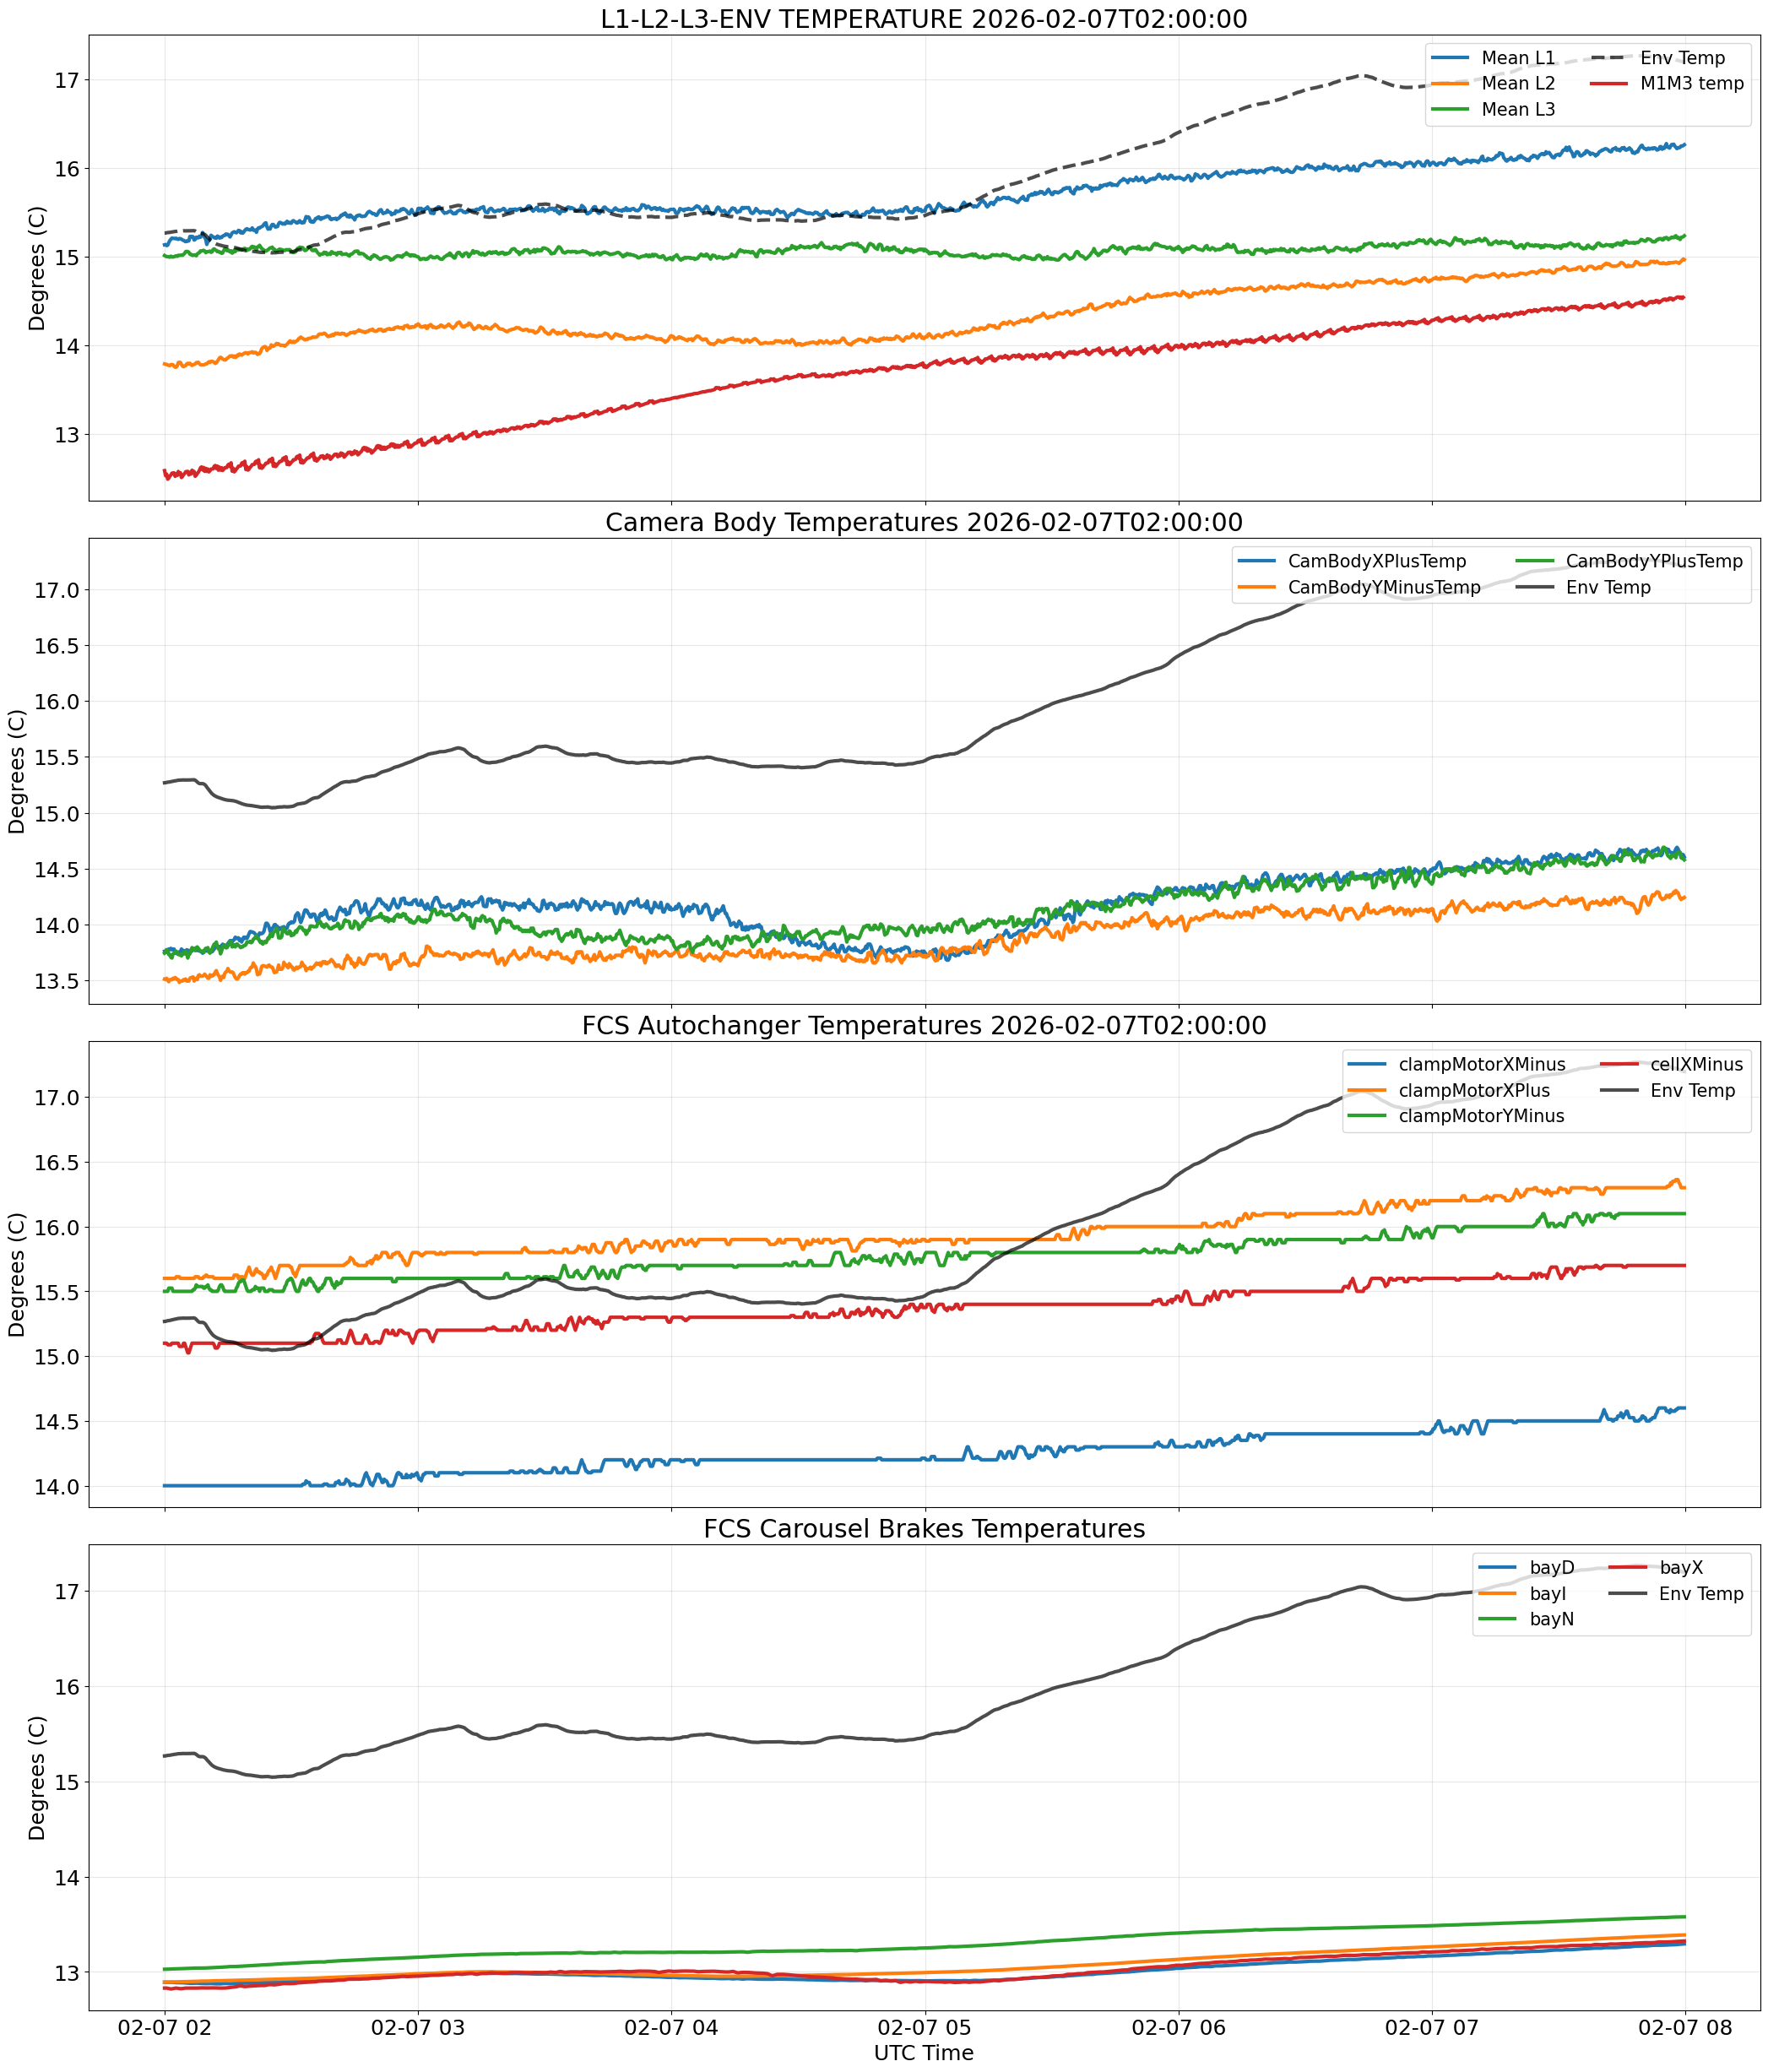

#----------------------------------------------------------------------------------------------------


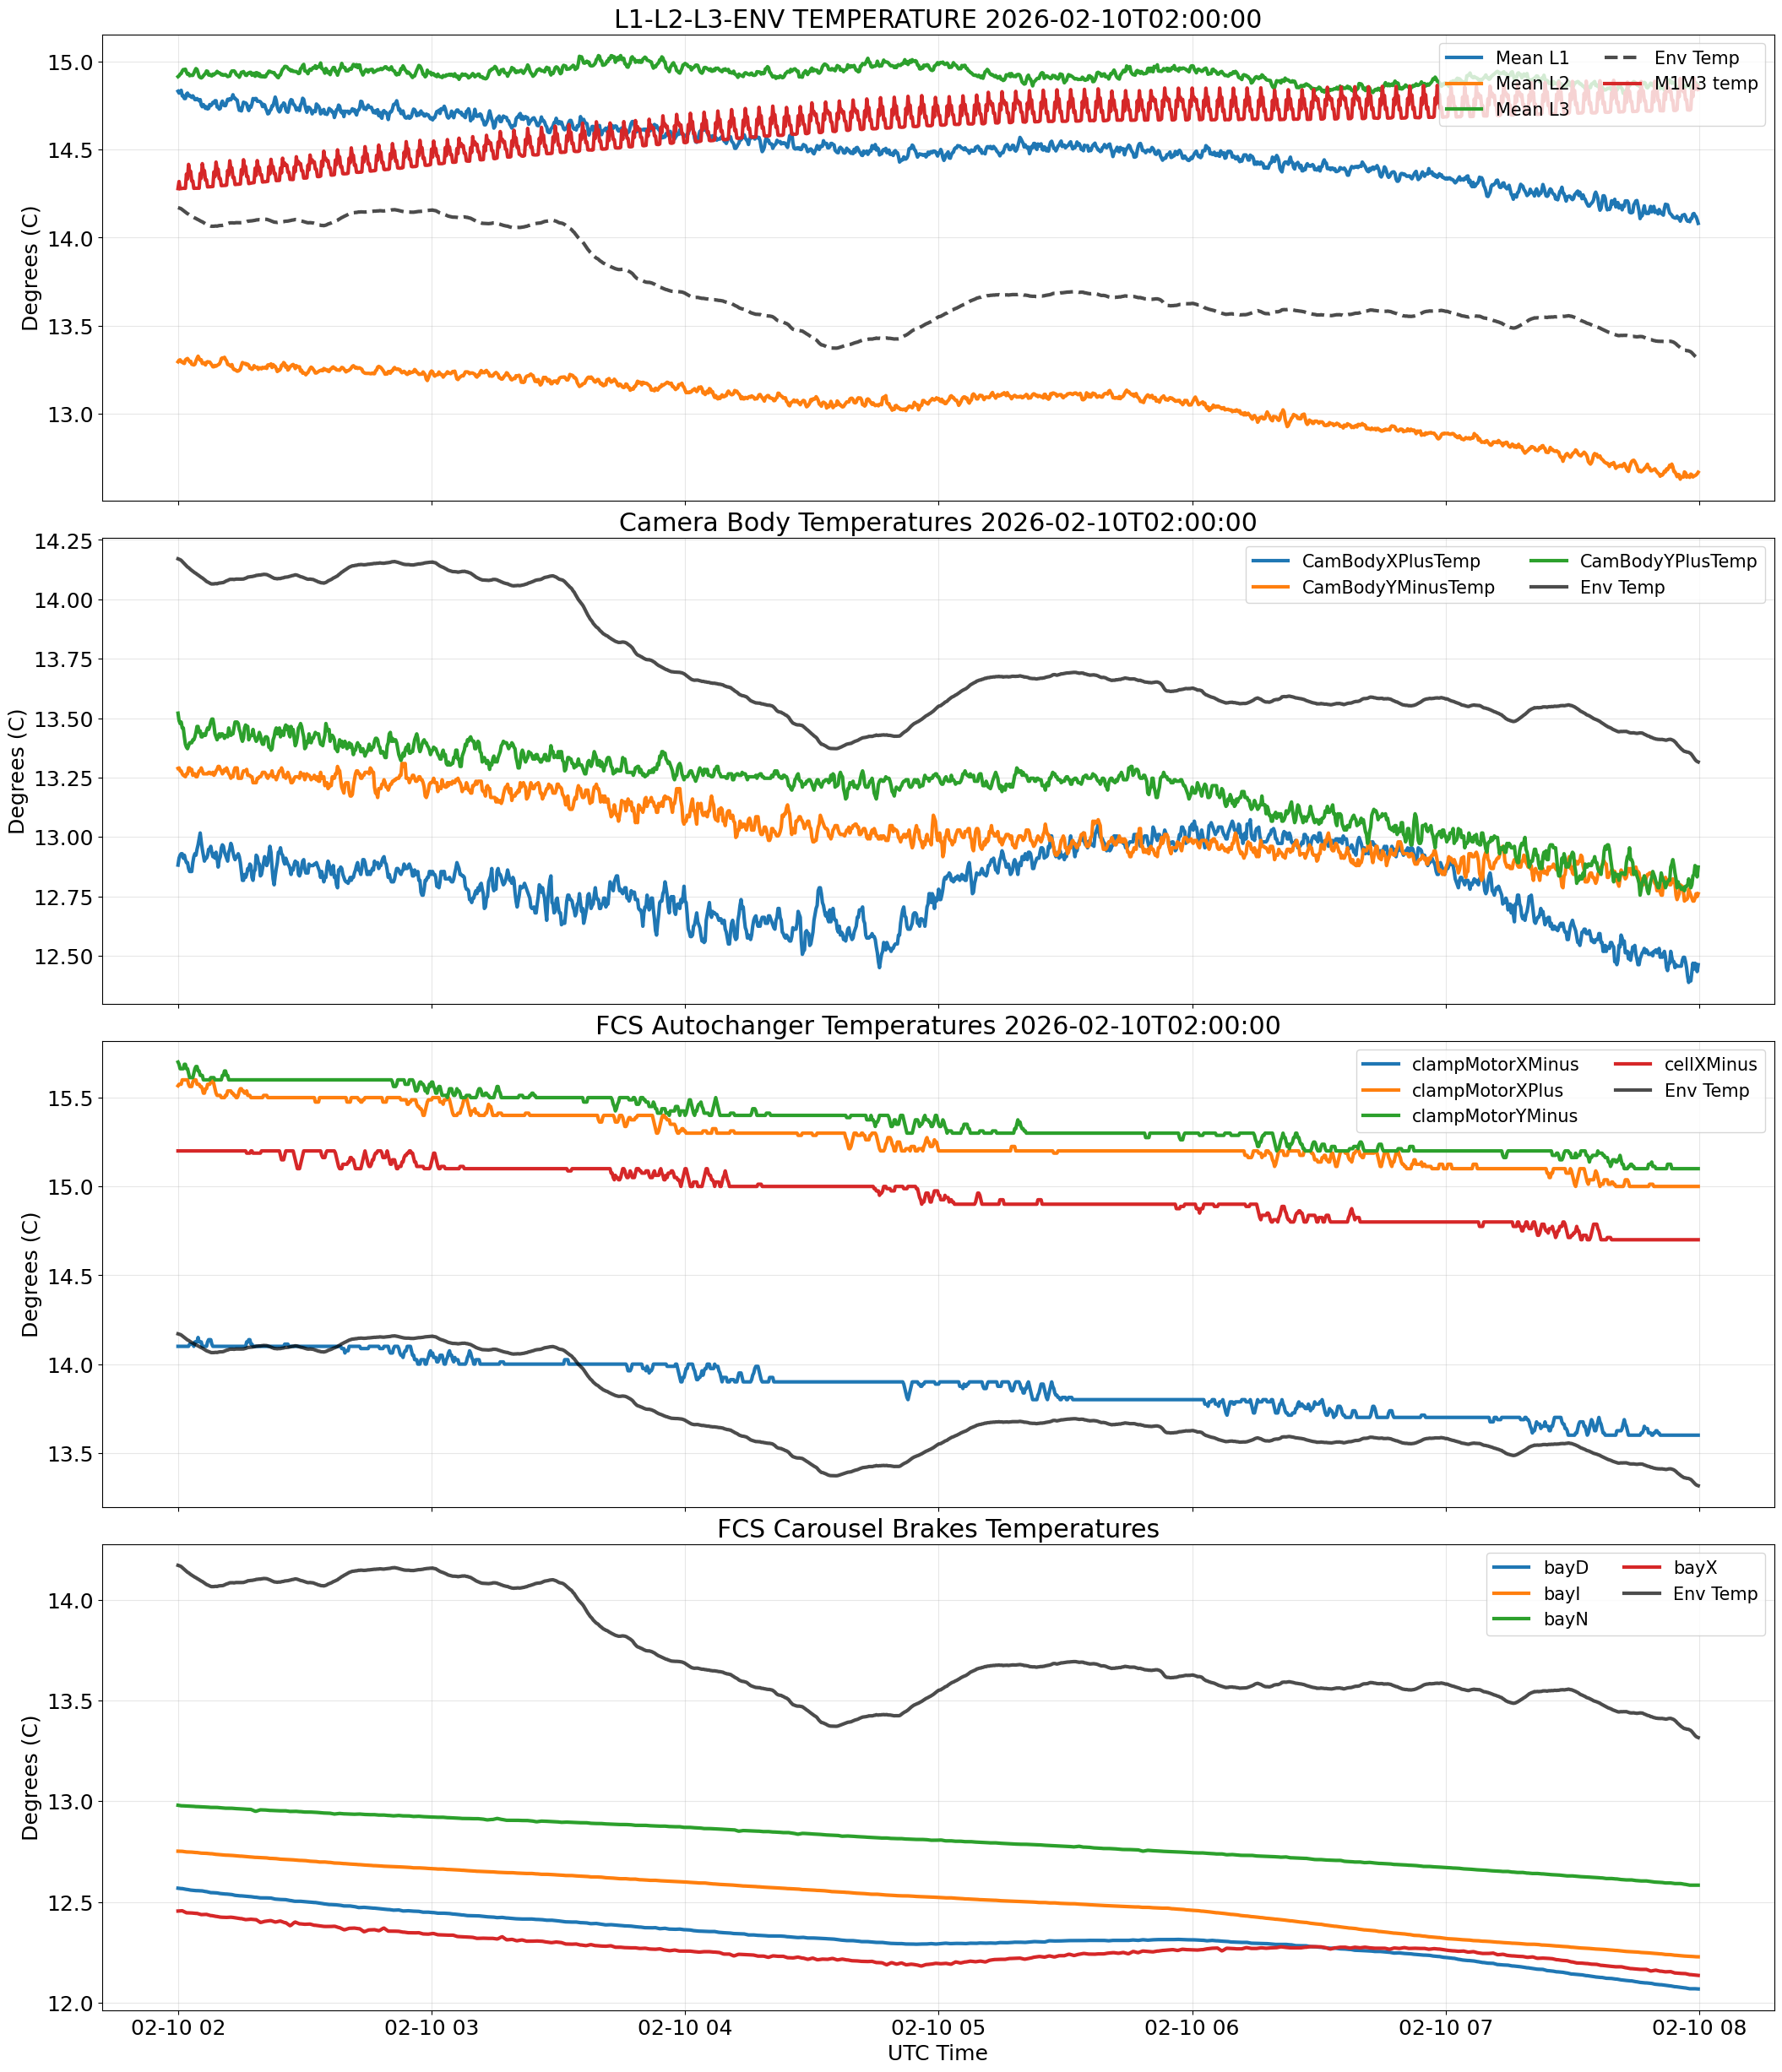

#----------------------------------------------------------------------------------------------------


In [44]:
import matplotlib.pyplot as plt
import pandas as pd
from astropy.time import Time, TimeDelta

# changes = ['2026-01-14T03:00:00','2026-01-29T00:45:00','2025-12-08T02:00:00','2025-12-08T04:20:00','2025-12-12T04:00:00','2025-12-13T05:00:00','2025-12-13T07:00:00']
changes=['2026-01-29T00:30:00.0','2026-01-14T02:00:00','2025-12-08T00:00:00','2025-12-11T00:00:00','2025-12-13T00:00:00','2026-02-07T02:00:00','2026-02-10T02:00:00'] #['2026-01-29T00:34:25.6'] #,'2026-01-13T04:54:17.1','2026-01-11T01:30:17.4','2026-01-11T07:45:03.3','2026-01-10T02:09:45.3','2026-01-10T07:01:16.4'

def smooth_to_15s(series, rolling_window='1min'):
    s = pd.Series(series).copy()
    s = pd.to_numeric(s, errors='coerce')
    s.index = pd.to_datetime(s.index, utc=True, errors='coerce')
    s = s[~s.index.isna()]
    s = s.dropna()
    if s.empty:
        return s
    s = s.groupby(level=0).mean().sort_index()
    s = s.resample('15s').mean().interpolate('time')
    s = s.rolling(rolling_window, center=True, min_periods=1).mean()
    return s

for time in changes:
    plt.rcParams.update({'font.size': 18}) # Base size for all text
    original_time_start = Time(time, scale="utc", format="isot")
    original_time_end = original_time_start + TimeDelta(6 * 3600, format='sec')
    time_start = original_time_start
    time_end = original_time_end
    
    indices = [114, 115, 116, 117]
    frames = []
    for idx in indices:
        df = await client.select_time_series(
            'lsst.sal.ESS.temperature',
            fields='*',
            start=time_start,
            end=time_end,
            index=idx
        )
        if not df.empty:
            df = df.copy()
            temp_cols = [f"temperatureItem{i}" for i in range(16) if f"temperatureItem{i}" in df.columns]
            df[temp_cols] = df[temp_cols].apply(pd.to_numeric, errors="coerce")

            # Mean across channels for this ESS index (per timestamp)
            df["temperature_mean"] = df[temp_cols].mean(axis=1, skipna=True)
            df["ess_index"] = idx

            # Keep only needed columns for cross-index averaging
            frames.append(df[["temperature_mean", "ess_index"]])

    if frames:
        m1m3_per_index = pd.concat(frames).sort_index()
        # Mean across the 4 ESS indices at each timestamp
        m1m3 = (
            m1m3_per_index
            .groupby(level=0)["temperature_mean"]
            .mean()
            .to_frame(name="temperature_mean_4idx")
            .sort_index()
        )
    else:
        m1m3 = pd.DataFrame(columns=["temperature_mean_4idx"])

    del frames[:]
    
    # Data Retrieval
    filt_log = (await client.select_time_series(
        'lsst.sal.MTCamera.command_setFilter',
        fields='*',
        start=time_start,
        end=time_end
    ))

    env_temp = (await client.select_time_series(
        'lsst.sal.ESS.temperature',
        fields='*',
        start=time_start,
        end=time_end,
        index=111
    ))

    splytemp = (await client.select_time_series(
        "lsst.sal.MTCamera.utiltrunk_VPC",
        fields=['splyAirTemp', 'retnAirTemp'],
        start=time_start,
        end=time_end
    ))

    cam_temp_body_util = (await client.select_time_series(
        "lsst.sal.MTCamera.utiltrunk_Body",
        fields=['l1XMinusTemp', 'l1XPlusTemp', 'l1YMinusTemp', 'l1YPlusTemp',
                'l2XMinusTemp', 'l2XPlusTemp', 'l2YMinusTemp', 'l2YPlusTemp'],
        start=time_start,
        end=time_end
    ))

    cam_temp_body = (await MTCAM_client.select_time_series(
        "lsst.MTCamera.utiltrunk_body",
        fields=['CamBodyXPlusTemp', 'CamBodyYMinusTemp', 'CamBodyYPlusTemp'],
        start=time_start,
        end=time_end
    ))

    autoch_temp = (await MTCAM_client.select_time_series(
        "lsst.MTCamera.fcs_autochanger_temperatures",
        fields='*',
        start=time_start,
        end=time_end
    ))

    carousel_breaks_temp = (await MTCAM_client.select_time_series(
        "lsst.MTCamera.fcs_carousel_brakes",
        fields='*',
        start=time_start,
        end=time_end
    ))

    # Calculations + 15s smoothing
    mean_L1_raw = cam_temp_body_util[['l1XMinusTemp', 'l1XPlusTemp', 'l1YMinusTemp', 'l1YPlusTemp']].mean(axis=1)
    mean_L2_raw = cam_temp_body_util[['l2XMinusTemp', 'l2XPlusTemp', 'l2YMinusTemp', 'l2YPlusTemp']].mean(axis=1)
    mean_L3_raw = splytemp[['splyAirTemp', 'retnAirTemp']].mean(axis=1)

    mean_L1 = smooth_to_15s(mean_L1_raw)
    mean_L2 = smooth_to_15s(mean_L2_raw)
    mean_L3 = smooth_to_15s(mean_L3_raw)
    env = smooth_to_15s(env_temp['temperatureItem0'])
    m1m3_smooth = smooth_to_15s(m1m3['temperature_mean_4idx'])

    # Plotting
    fig, axs = plt.subplots(nrows=4, ncols=1, figsize=(22, 26), sharex=True, gridspec_kw={'hspace': 0.08})
    plt.title(f'{time}')
    # --- Subplot 1: Utility Trunk VPC ---
    axs[0].set_title(f"L1-L2-L3-ENV TEMPERATURE {time}")
    axs[0].plot(mean_L1, label='Mean L1', linewidth=3)
    axs[0].plot(mean_L2, label='Mean L2', linewidth=3)
    axs[0].plot(mean_L3, label='Mean L3', linewidth=3)
    axs[0].plot(env, label='Env Temp', linestyle='--', color='black', alpha=0.7, linewidth=3)
    axs[0].plot(m1m3_smooth, label='M1M3 temp', linewidth=3)

    # --- Subplot 2: Camera Body ---
    axs[1].set_title(f"Camera Body Temperatures {time}")
    for probe in ['CamBodyXPlusTemp', 'CamBodyYMinusTemp', 'CamBodyYPlusTemp']:
        sm = smooth_to_15s(cam_temp_body[probe].dropna())
        if not sm.empty:
            axs[1].plot(sm, label=probe, linewidth=3)
    axs[1].plot(env, label='Env Temp', color='black', alpha=0.7, linewidth=3)

    # --- Subplot 3: FCS Autochanger ---
    axs[2].set_title(f"FCS Autochanger Temperatures {time}")
    for probe in ['clampMotorXMinus', 'clampMotorXPlus', 'clampMotorYMinus', 'cellXMinus']:
        subset = autoch_temp[autoch_temp['Location'] == probe]['temperature'].dropna()
        sm = smooth_to_15s(subset)
        if not sm.empty:
            axs[2].plot(sm, label=probe, linewidth=3)
    axs[2].plot(env, label='Env Temp', color='black', alpha=0.7, linewidth=3)

    # --- Subplot 4: Carousel Brakes ---
    axs[3].set_title("FCS Carousel Brakes Temperatures")
    for bay in ['bayD', 'bayI', 'bayN', 'bayX']:
        subset = carousel_breaks_temp[carousel_breaks_temp['Bay'] == bay]['temperature']
        sm = smooth_to_15s(subset)
        if not sm.empty:
            axs[3].plot(sm, label=bay, linewidth=3)
    axs[3].plot(env, label='Env Temp', color='black', alpha=0.7, linewidth=3)

    # Global formatting
    for ax in axs:
        # Add filter change vertical lines to all subplots
        for event in filt_log.index:
            ax.axvline(event, color='red', linestyle=':', alpha=0.5)
        ax.set_ylabel('Degrees (C)')
        ax.legend(loc='upper right', fontsize='small', ncol=2)
        ax.grid(True, alpha=0.3)

    axs[-1].set_xlabel('UTC Time')
    
    plt.subplots_adjust(left=0.05, right=0.95, top=0.95, bottom=0.05, hspace=0.1)
    # plt.savefig(f'filter_off_{time}.png')
    plt.show()

    filt_raw = autoch_temp[autoch_temp['Location'] == 'cellXMinus']['temperature']
    filt = smooth_to_15s(filt_raw)

    with open(f"temp_obs{time[:10]}.txt", "w", encoding="utf-8") as f:
        f.write(f"#Temperatures of environment and lenses/space between lenses \n")
        f.write(f"# ENV ---> L1 ---> L2 ---> FILTER ---> L3 ---> M1M3 \n")
        for variable in [env, mean_L1, mean_L2, filt, mean_L3, m1m3_smooth]:
            resampled = variable.resample("15min").mean().values
            np.savetxt(f, resampled[np.newaxis, :], fmt='%.2f', delimiter=' , ')
    print('#' + '-'*100)
    del m1m3

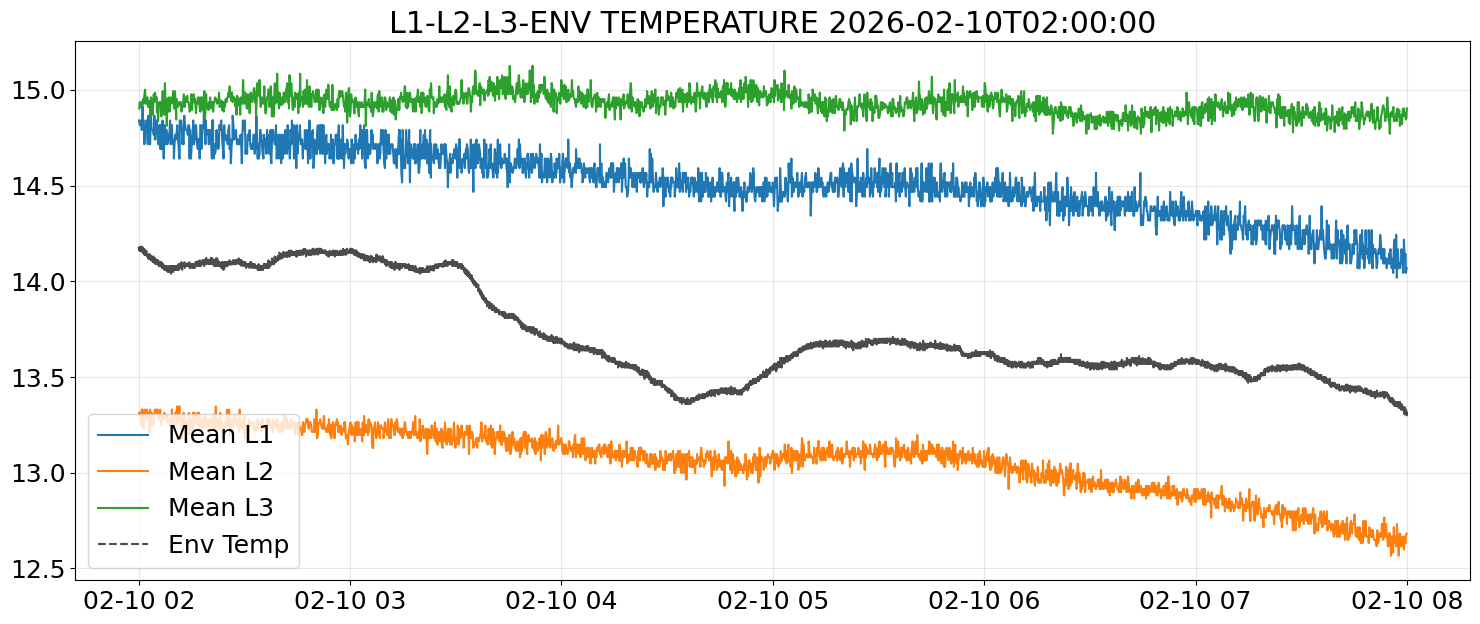

In [23]:
fig, axs = plt.subplots(nrows=1, ncols=1, figsize=(18,7), sharex=True, gridspec_kw={'hspace': 0.08})
plt.title(f'{time}')
# --- Subplot 1: Utility Trunk VPC ---
axs.set_title(f"L1-L2-L3-ENV TEMPERATURE {time}")
axs.plot(mean_L1, label='Mean L1')
axs.plot(mean_L2, label='Mean L2')
axs.plot(mean_L3, label='Mean L3')
axs.plot(env_temp['temperatureItem0'], label='Env Temp', linestyle='--' , color='black', alpha=0.7)
axs.legend()
axs.grid(True, alpha=0.3)


In [34]:
print(len(mean_L1), len(mean_L2), len(mean_L3), len(env_temp['temperatureItem0']))

2491 2491 2451 15534
